# Cross-modal Learning: Adapting TERRA to H&E with CellBridge

Transfer **TERRA’s molecular representations** to **H&E images** with **CellBridge**. Using paired H&E–Xenium data, train **LoRA adapters** and an alignment head on frozen **UNI2-h** to match TERRA embeddings. Then fit a cell-type classifier and calibrate ontology-aware predictions with **Cell-Ontology-Fallback (COF)**.

**You will:**
1. Load pretrained CellBridge weights.
2. Optionally prepare TERRA targets for UNI2-h adaptation (HEST-1k).
3. Extract H&E features and fit a cell-type classifier (NuCLS).
5. Generate ontology-aware prediction sets with the COF module.
6. Optionally conduct quantitative analysis.

:::{note}
A **GPU is recommended** for image encoding and **TERRA requires an NVIDIA GPU** for optional target preparation.
:::

## 1. Setup

From the repository root, create and activate a **Python 3.11** environment:

```bash
python3.11 -m venv .venv
source .venv/bin/activate
```
Install a [PyTorch build for your GPU](https://pytorch.org/get-started/locally/), then install CellBridge along with the notebook dependencies in the activated environment:

```bash
python -m pip install -e '.[models,preprocess,analysis]'
python -m pip install -r requirements/encoders.txt
python -m ipykernel install --user --name cellbridge --display-name 'CellBridge (Python 3.11)'
python -m jupyterlab notebooks/TUTORIAL.ipynb
```

For the optional TERRA section, also install `python -m pip install terra-st` following the [TERRA installation guide](https://terra-st.readthedocs.io/en/latest/installation.html).

Request access to [UNI2-h](https://huggingface.co/MahmoodLab/UNI2-h), accept the [HEST-1k dataset terms](https://huggingface.co/datasets/MahmoodLab/hest), and download the [CellBridge adapter](https://huggingface.co/ogutsevda/cellbridge).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from huggingface_hub import hf_hub_download

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/train/lora/cellbridge.yaml").is_file())
WORK = ROOT / "outputs" / "tutorial"
PAIRED = WORK / "data/train/hest"
NUCLS = WORK / "data/eval/nucls"
WORK.mkdir(parents=True, exist_ok=True)
print("Imports ready. Checking GPU availability...", flush=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PREPARE_PAIRED = True
RUN_COF = True

os.environ.update({
    "CELLBRIDGE_ROOT": str(ROOT),
    "CELLBRIDGE_DATA_ROOT": str(WORK / "data"),
    "CELLBRIDGE_OUTPUTS_ROOT": str(WORK / "results"),
    "CELLBRIDGE_CHECKPOINTS_ROOT": str(WORK / "checkpoints"),
})
print(f"Device: {DEVICE} | Outputs: {WORK}")

Imports ready. Checking GPU availability...
Device: cuda | Outputs: /lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/outputs/tutorial


In [ ]:
from huggingface_hub import get_token, notebook_login

if get_token() is None:
    notebook_login()

## 2. (Optional) Cross-modal alignment of TERRA and UNI2-h

If you set `PREPARE_PAIRED = False`, then you can skip this part, and directly use CellBridge in the next section.

If you would like to learn about the multi-modal pretraining step, please set `PREPARE_PAIRED = True`, and follow the example with two sections from HEST-1k below. You can also use custom paired datasets!

Below, we will download `NCBI876` (train) and `NCBI861` (validation), and extract TERRA cell embeddings. Check the [TERRA quickstart](https://terra-st.readthedocs.io/en/latest/notebooks/zero_shot_quickstart.html) for further details.

In [3]:
# Download registered H&E and transcripts, then reconstruct raw cell counts.
if PREPARE_PAIRED:
    import yaml
    from huggingface_hub import snapshot_download

    HEST_RAW = WORK / "hest_raw"
    sample_ids = ["NCBI876", "NCBI861"]
    snapshot_download(
        "MahmoodLab/hest", repo_type="dataset", local_dir=str(HEST_RAW),
        allow_patterns=["HEST_v1_3_0.csv"] + [
            name for sid in sample_ids for name in (
                f"wsis/{sid}.tif", f"transcripts/{sid}_transcripts.parquet",
            )
        ],
    )
    hest_meta = pd.read_csv(HEST_RAW / "HEST_v1_3_0.csv", low_memory=False).set_index("id")
    PAIRED.mkdir(parents=True, exist_ok=True)
    manifest = pd.DataFrame([{
        "id": sid,
        "wsi": str(HEST_RAW / f"wsis/{sid}.tif"),
        "transcripts": str(HEST_RAW / f"transcripts/{sid}_transcripts.parquet"),
        "pixel_size_um": float(hest_meta.loc[sid, "pixel_size_um_estimated"]),
        "output_dir": str(PAIRED / sid),
    } for sid in sample_ids])
    manifest.to_csv(PAIRED / "manifest.csv", index=False)
    pd.DataFrame({
        "sample_id": sample_ids, "split": ["distill_train", "distill_val"],
    }).to_csv(PAIRED / "splits.csv", index=False)
    PREPROCESS_CONFIG = WORK / "preprocess.yaml"
    PREPROCESS_CONFIG.write_text(yaml.safe_dump({
        "output_root": str(PAIRED), "qv_threshold": 20,
    }))
    display(manifest[["id", "pixel_size_um"]])

if PREPARE_PAIRED:
    for sid in sample_ids:
        print(f"Reconstructing counts for {sid}...", flush=True)
        result = subprocess.run([
            sys.executable, "-m", "cellbridge.preprocess.02_quality_check_streaming",
            "--config", str(PREPROCESS_CONFIG), "--sample-id", sid,
        ], capture_output=True, text=True)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

wsis/NCBI876.tif:   0%|          | 0.00/257M [00:00<?, ?B/s]

transcripts/NCBI861_transcripts.parquet:   0%|          | 0.00/265M [00:00<?, ?B/s]

transcripts/NCBI876_transcripts.parquet:   0%|          | 0.00/172M [00:00<?, ?B/s]

HEST_v1_3_0.csv: 0.00B [00:00, ?B/s]

wsis/NCBI861.tif:   0%|          | 0.00/394M [00:00<?, ?B/s]

,id,pixel_size_um
0,NCBI876,0.2125
1,NCBI861,0.2125


Reconstructing counts for NCBI876...
Reconstructing counts for NCBI861...


In [4]:
# Match retained cell IDs to H&E centers before exporting the 384-dimensional TERRA targets.
if PREPARE_PAIRED:
    import anndata as ad
    from terra import download_pretrained, harmonize_adata, tokenize_adata, embed_dataset

    MAX_TEACHER_CELLS = 2_000  # Demo targets per section.
    TOKEN_CACHE = Path("/tmp") / f"cellbridge-{os.getuid()}" / "terra_tokens"
    TOKEN_CACHE.mkdir(parents=True, exist_ok=True)

    assert torch.cuda.is_available(), "Run TERRA in an NVIDIA GPU environment."
    terra_dir = Path(download_pretrained("Lotfollahi-lab/TERRA-112M"))

if PREPARE_PAIRED:
    for sid in sample_ids:
        sample_dir = PAIRED / sid
        adata = ad.read_h5ad(sample_dir / f"{sid}.h5ad")
        assert adata.obs_names.is_unique
        adata.obs["cell_id"] = adata.obs_names.astype(str)
        # Harmonize raw counts against TERRA's gene vocabulary.
        harmonized = harmonize_adata(
            adata,
            gene_mapping_dict_file_path=str(terra_dir / "ensembl_dictionary.pkl"),
            gene_occurrence_count_file_path=str(terra_dir / "gene_count_dictionary.pkl"),
            min_cells_per_gene=10, min_genes_per_cell=10,
        )
        # Build neighborhoods from the full section before selecting demo targets.
        tokens = tokenize_adata(
            adata=harmonized, model_folder_path=str(terra_dir),
            cache_directory_path=str(TOKEN_CACHE / sid), nproc=4,
            keep_in_memory=True,
        )
        tokens = tokens.shuffle(seed=0).select(range(min(MAX_TEACHER_CELLS, len(tokens))))
        print(f"{sid}: embedding {len(tokens):,} target cells", flush=True)
        # Run frozen TERRA, then export the selected cell-level alignment targets.
        teacher = embed_dataset(
            dataset=tokens, model_folder_path=str(terra_dir), batch_size=128, num_workers=4,
        )
        cell_ids = np.asarray(tokens["cell_id"], dtype=str)
        centers = harmonized.obs.loc[cell_ids, ["he_x", "he_y"]]
        features = np.asarray(teacher["cell_emb"], dtype=np.float32)
        assert len(np.unique(cell_ids)) == len(cell_ids)
        assert features.shape == (len(cell_ids), 384)
        assert np.isfinite(features).all() and np.isfinite(centers.to_numpy()).all()
        np.savez(
            sample_dir / f"{sid}_terra.npz", cell_ids=cell_ids, cell_emb=features,
            he_x=centers.he_x.to_numpy(), he_y=centers.he_y.to_numpy(),
        )
        print(f"{sid}: saved {features.shape} teacher features")

/tmp/so25-cellbridge/venv/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/tmp/so25-cellbridge/venv/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

INFO:terra.inference.harmonize:STEP 1: DATA VALIDATION...
INFO:terra.inference.harmonize:Checking that adata.X contains raw counts...
INFO:terra.inference.harmonize:✓ adata.X contains raw counts (integer values).
INFO:terra.inference.harmonize:STEP 2: ADDING ENSEMBL IDS...
INFO:terra.inference.harmonize:Adding ensembl IDs from gene_mapping_dict with file path `/nfs/users/nfs_s/so25/.cache/huggingface/hub/models--Lotfollahi-lab--TERRA-112M/snapshots/00d1c977e49364ba10c28692abcbd102e115bf91/ensembl_dictionary.pkl`...
INFO:terra.inference.harmonize:Number of genes with matching ensembl IDs: 340.
INFO:terra.inference.harmonize:Filtering genes that have not occurred enough during pretraining...
INFO:terra.inference.harmonize:STEP 3: BASIC QUALITY CONTROL...
INFO:terra.inference.harmonize:Filtering cells with less than 10 genes.
INFO:terra.inference.harmonize:Before cell filtering: 12915 cells.
INFO:terra.inference.harmonize:After cell filtering: 12894 cells (removed 21 cells).
INFO:terra.in

/tmp/so25-cellbridge/venv/lib/python3.11/site-packages/terra/preprocessors/graph.py:26: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata,


INFO:terra.tokenizers.cell_tokenizers:Retrieving tokens for neighborhood cells.
INFO:terra.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:terra.tokenizers.cell_tokenizers:Using generator for dataset creation.


...

INFO:terra.tokenizers.cell_tokenizers:Formatting gene tokens...


Map (num_proc=4):   0%|          | 0/43877 [00:00<?, ? examples/s]

NCBI861: embedding 2,000 target cells
INFO:terra.inference.embed:STEP 1: LOADING CONFIG...
INFO:terra.inference.embed:STEP 2: GENERATING EMBEDDINGS...
INFO:terra.utils.helper:Protein-init: DISABLED -- using the default learnable nn.Embedding for gene tokens.
INFO:terra.utils.helper:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(13, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384,

0it [00:00, ?it/s]/tmp/so25-cellbridge/venv/lib/python3.11/site-packages/terra/inference/embed.py:265: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
16it [01:25,  5.36s/it]


NCBI861: saved (2000, 384) teacher features


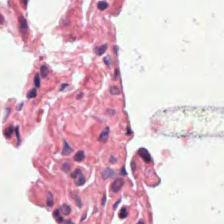

In [5]:
# Preview a paired crop: 112 × 112 µm resized to 224 × 224 pixels.
if PREPARE_PAIRED:
    from cellbridge.train.lora.data import crop_cell, open_wsi

    sid = sample_ids[0]
    row = manifest.set_index("id").loc[sid]
    with np.load(PAIRED / sid / f"{sid}_terra.npz", allow_pickle=False) as saved:
        cx, cy = float(saved["he_x"][0]), float(saved["he_y"][0])
    wsi = open_wsi(row.wsi)
    try:
        display(crop_cell(wsi, cx, cy, row.pixel_size_um))
    finally:
        wsi.store.close()

In [6]:
# Write an illustrative training config and print its command. This is only a simple example!
if PREPARE_PAIRED:
    import shlex
    from cellbridge.config import load_config

    train_cfg = load_config(ROOT / "configs/train/lora/cellbridge.yaml")
    train_cfg.update({
        "run_name": "tutorial_hest",
        "data_root": str(PAIRED), "splits_path": str(PAIRED / "splits.csv"),
        "output_dir": str(WORK / "training"),
        "checkpoint_dir": str(WORK / "checkpoints/tutorial_hest"),
        "max_cells_per_sample": 5000, "max_val_cells_per_sample": 2000,
    })
    train_cfg["training"].update({"max_steps": 20000, "eval_every": 1000, "patience": 5})
    TRAIN_CONFIG = WORK / "train.yaml"
    TRAIN_CONFIG.write_text(yaml.safe_dump(train_cfg, sort_keys=False))
    print(shlex.join(["cellbridge-train", "--config", str(TRAIN_CONFIG)]))

cellbridge-train --config /lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/outputs/tutorial/train.yaml


The **representative** training update is shown below:

```python
from cellbridge.train.lora.data import build_datasets
from cellbridge.train.lora.model import build_uni2_distiller, contrastive_loss
from cellbridge.train.lora.train import make_loader, make_optimizer

student = build_uni2_distiller(**train_cfg['model']).to(DEVICE)
train_data, val_data = build_datasets(train_cfg, student.eval_transforms)
loader = make_loader(train_data, train_cfg, training=True)
optimizer, _ = make_optimizer(student, train_cfg)
student.train()
for batch in loader:
    optimizer.zero_grad(set_to_none=True)
    image_z = student(batch['image'].to(DEVICE))['projected']
    target_z = student.project_terra(batch['terra'].to(DEVICE))
    loss = contrastive_loss(image_z, target_z, temperature=0.07)['loss_total']
    loss.backward()
    optimizer.step()
train_data.close()
val_data.close()
```

## 3. Load CellBridge

Load the released CellBridge adapter and its required UNI2-h backbone below.

In [7]:
from cellbridge.train.lora.model import load_checkpoint

LOCAL_CHECKPOINT = None
RELEASE = "1c334ee0783be5aaae93a5562522d73fc92ee6c1"
uni_weights = hf_hub_download("MahmoodLab/UNI2-h", filename="pytorch_model.bin")
checkpoint_path = Path(LOCAL_CHECKPOINT) if LOCAL_CHECKPOINT else Path(hf_hub_download(
    "ogutsevda/cellbridge", filename="cellbridge.pt", revision=RELEASE,
))
model, checkpoint = load_checkpoint(checkpoint_path, device=DEVICE, weights_path=uni_weights)
model.eval()
print(checkpoint["model_config"])

{'image_dim': 1536, 'terra_dim': 384, 'trainable_blocks': 4, 'lora_rank': 8, 'lora_alpha': 16.0, 'lora_dropout': 0.05, 'target_modules': ['qkv', 'proj'], 'alignment_dim': 384, 'projection_hidden_dim': None}


## 4. Extract image-only embeddings with CellBridge

Now that you have the CellBridge weights, let's walk through an example, with the NuCLS dataset! It provides H&E fields of view, cell coordinates, labels, and a fixed train/validation/test split for 59k cells. The command below downloads the dataset and prepares its existing annotations and splits.

In [8]:
subprocess.run([
    sys.executable, "-m", "cellbridge.inference.prepare.nucls", str(NUCLS),
], check=True)
metadata = pd.read_csv(NUCLS / "nucls_info.csv", dtype={"row_id": str, "cell_uid": str})
metadata = metadata.loc[metadata.label != "unlabeled"].copy()
assert metadata.row_id.is_unique and metadata.cell_uid.is_unique
assert metadata.groupby("slide_id").split.nunique().eq(1).all()
display(metadata.groupby("split").size().rename("cells").to_frame())

Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/src/cellbridge/inference/prepare/nucls.py", line 350, in <module>
    main()
  File "/lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/src/cellbridge/inference/prepare/nucls.py", line 339, in main
    validate_archive(archive) if archive.exists() else download_archive(archive)
                                                       ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/src/cellbridge/inference/prepare/nucls.py", line 78, in download_archive
    for block in iter(lambda: response.read(1024 * 1024), b""):
  File "/lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/src/cellbridge/inference/prepare/nucls.py", line 78, in <lambda>
    for block in iter(lambda: response.read(1024 * 1024), b""):
         

KeyboardInterrupt: 

In [ ]:
from cellbridge.inference.embed.crops import center_cell_crop

@torch.inference_mode()
def embed_cells(image, cells, batch_size=16):
    """Embed cells in input row order."""
    features = []
    for start in range(0, len(cells), batch_size):
        rows = cells.iloc[start:start + batch_size]
        patches = [model.eval_transforms(center_cell_crop(image, row, size=224))
                   for _, row in rows.iterrows()]
        images = torch.stack(patches).to(DEVICE)
        features.append(model.encode_images(images, use_lora=True).float().cpu().numpy())
    return np.concatenate(features)

# Inspect one cell and the available representations.
example = metadata.iloc[0]
with Image.open(NUCLS / "raw/rgb" / example.image_name) as source:
    image = np.asarray(source.convert("RGB"))
crop = center_cell_crop(image, example, size=224)
display(crop)
with torch.inference_mode():
    batch = model.eval_transforms(crop).unsqueeze(0).to(DEVICE)
    original_uni = model.encode_images(batch, use_lora=False)
    adapted = model.encode_images(batch, use_lora=True)
    projected = model.apply_heads(adapted)["projected"]
print("UNI2-h:", tuple(original_uni.shape), "CellBridge:", tuple(adapted.shape),
      "Alignment projection:", tuple(projected.shape))

In [ ]:
# Encode one field of view at a time and lower batch_size above if GPU memory is limited.
feature_blocks, row_ids = [], []
for image_name, cells_in_image in metadata.groupby("image_name", sort=False):
    with Image.open(NUCLS / "raw/rgb" / image_name) as source:
        image = np.asarray(source.convert("RGB"))
    feature_blocks.append(embed_cells(image, cells_in_image[["x", "y"]]))
    row_ids.extend(cells_in_image.row_id)
X = np.concatenate(feature_blocks)
row_ids = np.asarray(row_ids, dtype=str)
aligned = metadata.set_index("row_id").loc[row_ids].reset_index()
assert X.shape == (len(aligned), 1536)
np.savez(WORK / "nucls_cellbridge.npz", embeddings=X, row_ids=row_ids,
         cell_ids=aligned.cell_uid.to_numpy(dtype=str))
del feature_blocks
print(f"Saved {len(X):,} cell features to {WORK / 'nucls_cellbridge.npz'}")

## 4. Fit a task-specific classifier and predict labels

Fit one standardized logistic-regression classifier with fixed `C=1`. This is again an illustrative example!

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

train = aligned.split.eq("train").to_numpy()
y = aligned.label.to_numpy(dtype=str)
classifier = make_pipeline(
    StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=0),
)
classifier.fit(X[train], y[train])
scores = []
for split in ("val", "test"):
    selected = aligned.split.eq(split).to_numpy()
    assert set(y[selected]) <= set(classifier.classes_)
    predicted = classifier.predict(X[selected])
    scores.append({
        "split": split,
        "macro_f1": f1_score(y[selected], predicted, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y[selected], predicted),
    })
display(pd.DataFrame(scores).round(3))

In [ ]:
query_name = aligned.loc[aligned.split == "test", "image_name"].iloc[0]
query_cells = aligned.loc[aligned.image_name == query_name, ["cell_uid", "x", "y"]].rename(
    columns={"cell_uid": "cell_id"},
)
with Image.open(NUCLS / "raw/rgb" / query_name) as source:
    query_image = np.asarray(source.convert("RGB"))

query_features = embed_cells(query_image, query_cells)
probabilities = classifier.predict_proba(query_features)
predictions = query_cells.copy()
predictions["predicted_label"] = classifier.classes_[probabilities.argmax(axis=1)]
predictions["max_probability"] = probabilities.max(axis=1)
predictions.to_csv(WORK / "he_only_predictions.csv", index=False)
np.savez(WORK / "he_only_probabilities.npz",
         cell_ids=predictions.cell_id.to_numpy(dtype=str),
         classes=classifier.classes_.astype(str), probabilities=probabilities)
display(predictions.head())

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(query_image)
colours = plt.get_cmap("tab20")
for i, (label, cells_in_class) in enumerate(predictions.groupby("predicted_label")):
    ax.scatter(cells_in_class.x, cells_in_class.y, label=label,
               color=colours(i), s=18, edgecolors="black", linewidths=0.2)
ax.set_title("CellBridge predictions from H&E")
ax.axis("off")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Predicted cell type")
plt.show()

Save the task classifier together with its preprocessing and encoder settings. Reuse **the same adapter, UNI2-h backbone, feature representation, and crop convention** for new cells. The classifier file does not contain either encoder's weights.

In [ ]:
import joblib

joblib.dump({
    "classifier": classifier,
    "adapter_path": str(checkpoint_path),
    "adapter_repo": None if LOCAL_CHECKPOINT else "ogutsevda/cellbridge",
    "adapter_revision": None if LOCAL_CHECKPOINT else RELEASE,
    "uni_weights_path": uni_weights,
    "representation": "lora_adapted",
    "crop": {"source_size": 224, "fill": 255},
}, WORK / "nucls_classifier.joblib")
print(f"Classifier, features, and predictions saved under {WORK}")

## 6. Optional: calibrate Cell-Ontology-Fallback (COF)

With `RUN_COF = True`, reuse the image features from section 3 to fit and calibrate ontology-aware prediction sets. No additional image encoding or TERRA inference is needed.

COF uses a **separate classifier** because it maps the task labels into the ontology and reserves validation cells for calibration. Its PCA and classifier are fitted on training cells; classifier regularization is selected within training data. Ontology mapping and minimum class support can exclude some cells. These predictions therefore need not match the simple classifier in section 4.

We use the supplied NuCLS ontology mapping and a **90% target coverage** (`alpha=0.1`). The reported test coverage is empirical; the target is not a guarantee for an arbitrary new tissue or shifted dataset. `branch_graph` is CellBridge's COF method.

In [ ]:
if RUN_COF:
    from cellbridge.config import load_config
    from cellbridge.inference.conformal import conformal_ood
    from cellbridge.ontology import load_mapping, load_ontology

    cfg = load_config(ROOT / "configs/inference/nucls.yaml")
    settings = cfg["conformal"]
    mapping = load_mapping(settings["mapping"])
    ontology = load_ontology(settings["ontology"])
    task = conformal_ood.prepare_task(
        X, aligned, mapping, task="all", arm="lora_adapted",
        pca_components=cfg["probe"]["pca_components"],
        min_class_count_per_split=settings["min_class_count_per_split"],
        seed=cfg["probe"]["seed"],
    )
    cof_result = conformal_ood.evaluate(
        task, "linear", cfg["probe"]["linear"], mapping, ontology,
        branch_roots=settings["branch_roots"], alpha=settings["alpha"],
    )
    COF = WORK / "results/nucls/conformal_prediction"
    conformal_ood.save_result(COF, cof_result)
    cof_metrics = pd.read_csv(COF / "metrics.csv")
    display(cof_metrics.loc[cof_metrics.conformal_method == "branch_graph", [
        "marginal_coverage", "mean_prediction_set_size", "singleton_rate",
    ]].round(3))

### Inspect cell-level prediction sets

A singleton set retains one label; a larger set retains multiple plausible labels and can support a broader ontology category. Join predictions back to the image using saved cell identities.

The plot retains the original tutorial's set-size score, `1 − |C| / |Y|`, to show how specific each prediction is. It is not the probability that the prediction is correct. Empty sets are marked separately.

In [ ]:
if RUN_COF:
    with np.load(COF / "predictions.npz", allow_pickle=False) as saved:
        classes = saved["classes"].astype(str)
        sets = saved["branch_graph_sets"]
        cof_predictions = pd.DataFrame({
            "row_id": saved["ids"].astype(str),
            "true_label": saved["y_true"].astype(str),
            "prediction_set": [", ".join(classes[mask]) for mask in sets],
            "set_size": sets.sum(axis=1),
        })

    # Join by saved cell identity, not by CSV row order.
    cof_predictions = cof_predictions.merge(
        metadata[["row_id", "image_name"]], on="row_id", validate="one_to_one",
    )
    display(cof_predictions.head(10))
    print(f"COF results are saved under {COF}")

In [ ]:
if RUN_COF:
    # Qualitative inspection: paper Eq. 10, R = 1 - |C| / |Y|.
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D

    with np.load(COF / "predictions.npz", allow_pickle=False) as saved:
        top1 = pd.DataFrame({
            "row_id": saved["ids"].astype(str),
            "predicted_label": classes[saved["probabilities"].argmax(axis=1)],
        })
    view = cof_predictions.merge(top1, on="row_id", validate="one_to_one").merge(
        metadata[["row_id", "x", "y"]], on="row_id", validate="one_to_one",
    )
    view["reliability"] = 1 - view["set_size"] / len(classes)
    image_name = view["image_name"].value_counts().index[0]  # Change to inspect another image.
    cells = view.loc[view["image_name"] == image_name]
    with Image.open(NUCLS / "raw/rgb" / image_name) as image:
        tissue = np.asarray(image.convert("RGB"))

    fig, axes = plt.subplots(1, 4, figsize=(17, 5), layout="constrained")
    for ax, title in zip(axes, ["H&E", "Reference labels", "Predicted labels (top-1)", "Reliability score"]):
        ax.imshow(tissue)
        ax.set_title(title)
        ax.axis("off")
    colours = plt.get_cmap("tab20", len(classes))
    for ax, column in zip(axes[1:3], ["true_label", "predicted_label"]):
        codes = pd.Categorical(cells[column], categories=classes).codes
        ax.scatter(cells.x, cells.y, c=codes, cmap=colours, vmin=-0.5,
                   vmax=len(classes) - 0.5, s=24, edgecolors="black", linewidths=0.3)
    nonempty = cells["set_size"] > 0
    points = axes[3].scatter(cells.loc[nonempty, "x"], cells.loc[nonempty, "y"],
                             c=cells.loc[nonempty, "reliability"], cmap="RdYlGn",
                             vmin=0, vmax=1, s=24, edgecolors="black", linewidths=0.3)
    if (~nonempty).any():
        axes[3].scatter(cells.loc[~nonempty, "x"], cells.loc[~nonempty, "y"],
                        c="gray", marker="x", s=30, label="Empty set")
        axes[3].legend(loc="lower right")
    fig.colorbar(points, ax=axes[3], label="1 − set size / number of classes", shrink=0.7)
    handles = [Line2D([], [], marker="o", linestyle="", color=colours(i), label=label)
               for i, label in enumerate(classes)]
    fig.legend(handles=handles, loc="outside lower center", ncol=4, title="Cell types")
    fig.suptitle(f"{image_name} · {len(cells)} evaluated test cells")
    plt.show()

Outputs are saved under `outputs/tutorial/`:

- `nucls_cellbridge.npz`: image features and cell identities.
- `nucls_classifier.joblib`: the section 4 classifier and encoder/crop settings.
- `he_only_predictions.csv` and `he_only_probabilities.npz`: section 5 predictions.
- `results/nucls/conformal_prediction/`: optional COF metrics, prediction sets, and graph anchors.

To apply this to your own task:

1. Register paired expression and H&E data, preserve cell identity, and export the TERRA NPZ files from section 2.
2. Train an encoder with the section 2 command, or use released CellBridge weights. Encoder adaptation needs paired data; fitting a classifier on released image features needs only labeled images.
3. Extract reference image features and fit a classifier for your annotations using independent donor/slide splits.
4. Detect cells in new H&E images, crop them using the same convention, and apply that encoder and classifier. Neither TERRA nor expression data is needed here.

For whole-slide H&E, use `open_wsi` and `crop_cell` from `cellbridge.train.lora.data` to read regions lazily. For a HEST-style task, use the 112 µm field of view for **both** reference and query cells and refit the classifier. Do not apply the NuCLS classifier to a different crop convention without validation.

See the [TERRA tutorials](https://terra-st.readthedocs.io/en/latest/tutorials.html) for additional uses of the molecular embeddings, and the [reproducibility guide](../REPRODUCIBILITY.md) for full CellBridge experiments.